Code For Testing Model:

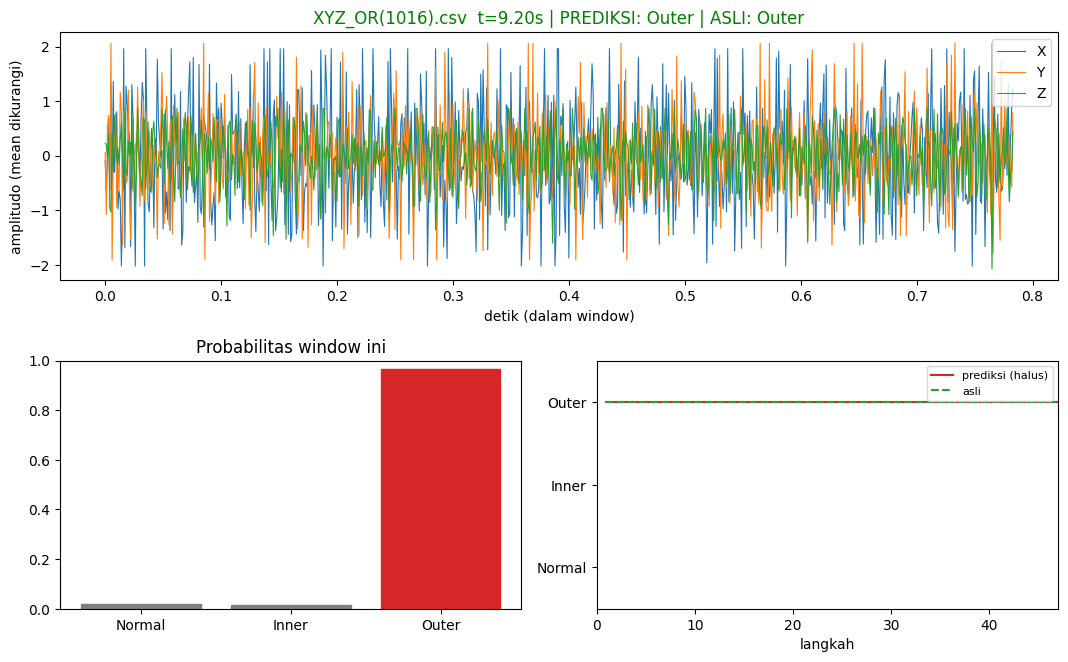

#00040 t=  7.80s XYZ_OR(1016).csv     mentah=Outer   conf=0.97 halus=Outer   asli=Outer   OK
#00041 t=  8.00s XYZ_OR(1016).csv     mentah=Outer   conf=0.96 halus=Outer   asli=Outer   OK
#00042 t=  8.20s XYZ_OR(1016).csv     mentah=Outer   conf=0.96 halus=Outer   asli=Outer   OK
#00043 t=  8.40s XYZ_OR(1016).csv     mentah=Outer   conf=0.97 halus=Outer   asli=Outer   OK
#00044 t=  8.60s XYZ_OR(1016).csv     mentah=Outer   conf=0.97 halus=Outer   asli=Outer   OK
#00045 t=  8.80s XYZ_OR(1016).csv     mentah=Outer   conf=0.97 halus=Outer   asli=Outer   OK
#00046 t=  9.00s XYZ_OR(1016).csv     mentah=Outer   conf=0.97 halus=Outer   asli=Outer   OK
#00047 t=  9.20s XYZ_OR(1016).csv     mentah=Outer   conf=0.97 halus=Outer   asli=Outer   OK

Selesai: 47 langkah dalam 11.1 s
Waktu inferensi rata-rata 11.1 ms/window (batas real-time pada hop 200: 200 ms) -> cukup cepat
Akurasi per langkah: mentah 100.0% | halus (mayoritas 5 terakhir) 100.0%
  XYZ_OR(1016).csv       suara mayoritas: Outer   (asl

In [5]:
# %% [CELL 1] (Opsional) Siapkan file di Google Colab -- hapus tanda # lalu jalankan sekali
# Cara A: unggah manual lewat panel Files (ikon folder di kiri), tarik best_lstm_subf_v3.pt dan folder CSV ke sana.
# Cara B: dari Google Drive
#   from google.colab import drive
#   drive.mount('/content/drive')
#   # lalu isi CKPT_PATH dan DATA_DIR di sel berikutnya dengan path di Drive, mis.
#   # "/content/drive/MyDrive/subf/best_lstm_subf_v3.pt"
# Cara C: unggah zip data lalu ekstrak
#   from google.colab import files; files.upload()      # pilih data.zip
#   !unzip -q data.zip -d data


# %% [CELL 2] KONFIGURASI -- ubah nilai di sini saja
MODE = "live"          # "eval" = evaluasi per file | "live" = replay langkah demi langkah

CKPT_PATH = "ai-model-1.0.pt"   # checkpoint hasil subf_dataset_training_v3.py
DATA_DIR = "data"                    # folder berisi CSV (dicari sampai subfolder)

# File yang diuji. Gunakan HANYA file test (baris "File test:" di keluaran training).
# Kosongkan ([]) untuk memakai semua file -> akan termasuk file training, akurasinya tidak bermakna.
TEST_FILES = []

SRC_HZ = 1000              # sampling rate CSV. Selain 1000 (mis. 1600 untuk ADXL345) -> di-resample ke 1000 Hz
FALLBACK_NO_NORM = False   # True: jika checkpoint tidak punya mu/sd, tetap jalan TANPA normalisasi (hanya untuk diagnosa)

# --- khusus MODE = "eval" ---
EVAL_STRIDE = None         # None = pakai stride dari checkpoint
RESULTS_CSV = "hasil.csv"  # None = tidak disimpan
SHOW_CONFUSION_PLOT = True

# --- khusus MODE = "live" ---
LIVE_FILES = None  # ["XYZ_N(2).csv", "XYZ_OR(7).csv"]   # diputar berurutan; None = pakai TEST_FILES
LIVE_HOP = None            # sampel baru per langkah; None = stride dari checkpoint (mis. 200 = 200 ms data)
LIVE_SPEED = 1.0           # 1 = waktu nyata, 10 = 10x lebih cepat, 0 = secepatnya
LIVE_DELAY_SEC = None      # jeda tetap per langkah dalam detik (mis. 0.001); menggantikan LIVE_SPEED
LIVE_SMOOTH = 5            # prediksi "halus" = mayoritas dari N prediksi terakhir
LIVE_MAX_STEPS = 0         # 0 = sampai semua file habis
LIVE_PLOT = True           # True = grafik live; False = hanya teks
LIVE_PLOT_EVERY = 2        # gambar ulang grafik tiap N langkah (menggambar di notebook ~0.1-0.3 detik)
LIVE_LOG_LINES = 8         # jumlah baris log terakhir yang ditampilkan di bawah grafik


# %% [CELL 3] KODE INTI -- tidak perlu diubah
import os
import re
import glob
import time
from collections import deque
from math import gcd

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

FS_MODEL = 1000
LABEL_RX = re.compile(r"XYZ_(N|IR|OR)", re.IGNORECASE)
LABEL_ID = {"N": 0, "IR": 1, "OR": 2}
DEFAULT_CLASSES = ["Healthy / Normal", "Inner Race Fault", "Outer Race Fault"]

try:
    from IPython import get_ipython
    from IPython.display import display, clear_output
    _ip = get_ipython()
    IN_NOTEBOOK = _ip is not None and _ip.__class__.__name__ != "TerminalInteractiveShell"
except Exception:
    IN_NOTEBOOK = False


class VibrationBiLSTM(nn.Module):
    def __init__(self, input_size=3, hidden_dim=64, num_layers=2, num_classes=3, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_dim, num_layers=num_layers,
                            batch_first=True, bidirectional=True,
                            dropout=dropout if num_layers > 1 else 0.0)
        self.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden_dim * 2, 32),
                                nn.ReLU(), nn.Linear(32, num_classes))

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out.mean(dim=1))


def load_checkpoint(path=None):
    path = path or CKPT_PATH
    if not os.path.exists(path):
        raise FileNotFoundError(f"Checkpoint '{path}' tidak ditemukan. Isi folder saat ini: {sorted(os.listdir('.'))[:20]}")
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    try:
        ck = torch.load(path, map_location=device, weights_only=True)
    except Exception as e:
        print(f"⚠ weights_only=True gagal ({type(e).__name__}); memuat dengan weights_only=False. "
              f"Lakukan ini hanya untuk checkpoint buatan Anda sendiri.")
        ck = torch.load(path, map_location=device, weights_only=False)
    cfg, state = ck.get("config", {}), ck["model_state_dict"]
    classes = cfg.get("classes", DEFAULT_CLASSES)
    window = int(cfg.get("window_size", 784))
    stride = int(cfg.get("stride", 200))
    mu, sd = cfg.get("mu"), cfg.get("sd")
    if mu is None or sd is None:
        if not FALLBACK_NO_NORM:
            raise ValueError("Checkpoint tidak memuat mu/sd (bukan dari subf_dataset_training_v3.py). "
                             "Untuk diagnosa saja, set FALLBACK_NO_NORM = True.")
        print("⚠⚠ mu/sd TIDAK ADA: input dijalankan tanpa normalisasi global. Prediksi bisa menyimpang jauh.")
        mu, sd = np.zeros((1, 1, 3), np.float32), np.ones((1, 1, 3), np.float32)
    else:
        mu = (mu.cpu().numpy() if isinstance(mu, torch.Tensor) else np.asarray(mu)).astype(np.float32)
        sd = (sd.cpu().numpy() if isinstance(sd, torch.Tensor) else np.asarray(sd)).astype(np.float32)
    hidden = state["lstm.weight_hh_l0"].shape[1]
    layers = sum(1 for k in state if re.fullmatch(r"lstm\.weight_ih_l\d+", k))
    model = VibrationBiLSTM(int(cfg.get("input_size", 3)), hidden, layers, len(classes)).to(device)
    model.load_state_dict(state)
    model.eval()
    info = dict(classes=classes, window=window, stride=stride, device=device)
    print(f"✓ Checkpoint: {path} | kelas: {classes} | window {window} ({window / FS_MODEL:.3f} s) | "
          f"stride {stride} | perangkat {device}")
    return model, mu, sd, info


@torch.no_grad()
def predict_probs(model, Xn, device, bs=256):
    out = []
    for i in range(0, len(Xn), bs):
        out.append(torch.softmax(model(torch.from_numpy(Xn[i:i + bs]).to(device)), dim=1).cpu().numpy())
    return np.concatenate(out)


def read_signal(path):
    df = pd.read_csv(path, header=None)
    if df.shape[1] < 3:
        raise ValueError("kolom < 3")
    sig = df.iloc[:, :3].values.astype(np.float32)
    if not np.isfinite(sig).all():
        raise ValueError("berisi NaN/inf")
    if abs(SRC_HZ - FS_MODEL) > 1e-6:
        if SRC_HZ < FS_MODEL:
            raise ValueError(f"SRC_HZ {SRC_HZ} < {FS_MODEL}: tidak bisa disetarakan")
        from scipy.signal import resample_poly
        g = gcd(int(round(SRC_HZ)), FS_MODEL)
        sig = resample_poly(sig, FS_MODEL // g, int(round(SRC_HZ)) // g, axis=0).astype(np.float32)
    return sig


def make_windows(sig, window, hop):
    starts = np.arange(0, len(sig) - window + 1, hop)
    if len(starts) == 0:
        return np.zeros((0, window, 3), np.float32), starts
    W = np.stack([sig[s:s + window] for s in starts])
    return W - W.mean(axis=1, keepdims=True), starts


def label_of(path):
    m = LABEL_RX.search(os.path.basename(path))
    return LABEL_ID[m.group(1).upper()] if m else None


def collect_files(names):
    allf = sorted(f for f in glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True)
                  if not os.path.basename(f).startswith("."))
    if not allf:
        here = sorted(os.listdir(DATA_DIR))[:20] if os.path.isdir(DATA_DIR) else "(folder tidak ada)"
        raise FileNotFoundError(f"Tidak ada CSV di DATA_DIR='{DATA_DIR}'. Isinya: {here}")
    if not names:
        print("⚠ Daftar file kosong: SEMUA file dipakai, termasuk file TRAINING. "
              "Akurasi yang keluar tidak bisa dianggap performa pada data baru.\n")
        return allf
    sel, missing = [], []
    for n in names:
        hit = [f for f in allf if os.path.basename(f).lower() == os.path.basename(n).lower()]
        if hit:
            sel.append(hit[0])
        else:
            missing.append(n)
    if missing:
        raise FileNotFoundError(f"File tidak ditemukan di '{DATA_DIR}': {missing}. "
                                f"Contoh file yang ada: {[os.path.basename(f) for f in allf[:8]]}")
    return sel


def scale_warning(W, sd, name):
    ratio = W.std(axis=(0, 1)) / sd.ravel()
    if np.any(ratio > 4) or np.any(ratio < 0.25):
        print(f"⚠ {name}: skala sinyal berbeda jauh dari data latih (rasio std per sumbu = {np.round(ratio, 2)}). "
              f"Cek satuan (g vs m/s²) atau gain sensor; prediksi bisa tidak valid.")


def short_names(classes):
    return ["Normal", "Inner", "Outer"] if len(classes) == 3 else [c.split()[0] for c in classes]


def show_table(df):
    if IN_NOTEBOOK:
        display(df)
    else:
        print(df.to_string(index=False))


# ------------------------------------------------------------------ EVAL
def run_eval():
    model, mu, sd, info = load_checkpoint()
    classes, device, K = info["classes"], info["device"], len(info["classes"])
    window, hop = info["window"], EVAL_STRIDE or info["stride"]
    files = collect_files(TEST_FILES)
    print(f"Window {window} sampel, stride {hop}, {len(files)} file\n")

    rows, all_p, all_t = [], [], []
    ok_files = n_lab = 0
    for path in files:
        name = os.path.basename(path)
        try:
            sig = read_signal(path)
        except Exception as e:
            print(f"! {name}: {e}, dilewati")
            continue
        W, _ = make_windows(sig, window, hop)
        if len(W) == 0:
            print(f"! {name}: lebih pendek dari satu window, dilewati")
            continue
        scale_warning(W, sd, name)
        probs = predict_probs(model, ((W - mu) / sd).astype(np.float32), device)
        pw = probs.argmax(1)
        votes = np.bincount(pw, minlength=K)
        fp = int(votes.argmax())
        true = label_of(path)
        if true is not None:
            n_lab += 1
            ok_files += int(fp == true)
            all_p.append(pw)
            all_t.append(np.full(len(pw), true))
        rows.append({"file": name, "asli": classes[true] if true is not None else "", "prediksi": classes[fp],
                     "benar": ("OK" if fp == true else "SALAH") if true is not None else "",
                     "window": len(pw), "conf_rata2": round(float(probs[:, fp].mean()), 3),
                     **{f"vote_{c}": int(v) for c, v in zip(classes, votes)}})
    if not rows:
        raise RuntimeError("Tidak ada file yang berhasil diproses.")
    df = pd.DataFrame(rows)
    show_table(df)

    if n_lab:
        from sklearn.metrics import classification_report, confusion_matrix
        p, t = np.concatenate(all_p), np.concatenate(all_t)
        cm = confusion_matrix(t, p, labels=list(range(K)))
        print(f"\nAkurasi per file  : {ok_files}/{n_lab}")
        print(f"Akurasi per window: {100 * (p == t).mean():.1f}%  ({len(p)} window; antar-window saling tumpang tindih, "
              f"sampel independen sebenarnya = {n_lab} file)\n")
        print(classification_report(t, p, labels=list(range(K)), target_names=classes, zero_division=0))
        if SHOW_CONFUSION_PLOT:
            fig, ax = plt.subplots(figsize=(4.8, 4))
            ax.imshow(cm, cmap="Blues")
            names_s = short_names(classes)
            ax.set_xticks(range(K)); ax.set_xticklabels(names_s)
            ax.set_yticks(range(K)); ax.set_yticklabels(names_s)
            ax.set_xlabel("prediksi"); ax.set_ylabel("asli"); ax.set_title("Confusion matrix (per window)")
            for i in range(K):
                for j in range(K):
                    ax.text(j, i, cm[i, j], ha="center", va="center",
                            color="white" if cm[i, j] > cm.max() / 2 else "black")
            fig.tight_layout()
            plt.show()
    if RESULTS_CSV:
        df.to_csv(RESULTS_CSV, index=False)
        print(f"Hasil per file disimpan ke {RESULTS_CSV}")
    return df


# ------------------------------------------------------------------ LIVE
def run_live():
    model, mu, sd, info = load_checkpoint()
    classes, device, K = info["classes"], info["device"], len(info["classes"])
    names_s = short_names(classes)
    window, hop = info["window"], LIVE_HOP or info["stride"]
    files = collect_files(LIVE_FILES if LIVE_FILES else TEST_FILES)
    delay = LIVE_DELAY_SEC if LIVE_DELAY_SEC is not None else (hop / FS_MODEL / LIVE_SPEED if LIVE_SPEED > 0 else 0.0)

    stream = []
    for path in files:
        try:
            sig = read_signal(path)
        except Exception as e:
            print(f"! {os.path.basename(path)}: {e}, dilewati")
            continue
        W, starts = make_windows(sig, window, hop)
        if len(W):
            scale_warning(W, sd, os.path.basename(path))
        for w, s in zip(W, starts):
            stream.append((os.path.basename(path), label_of(path), w, s / FS_MODEL))
    if not stream:
        raise RuntimeError("Tidak ada window untuk di-replay.")
    if LIVE_MAX_STEPS:
        stream = stream[:LIVE_MAX_STEPS]
    print(f"Replay {len(stream)} langkah | 1 langkah = {hop} sampel = {hop / FS_MODEL * 1000:.0f} ms data | "
          f"jeda target {delay * 1000:.1f} ms/langkah")
    if LIVE_PLOT and IN_NOTEBOOK and delay < 0.3:
        print("ℹ Menggambar ulang grafik di notebook butuh ~0.1-0.3 detik, jadi tampilan tidak bisa secepat "
              "jeda target. Naikkan LIVE_PLOT_EVERY atau set LIVE_PLOT = False untuk kecepatan penuh.")
    print()

    gui = LIVE_PLOT
    if gui:
        if not IN_NOTEBOOK:
            plt.ion()
        fig = plt.figure(figsize=(11, 6.5))
        ax1 = fig.add_subplot(2, 2, (1, 2)); ax2 = fig.add_subplot(2, 2, 3); ax3 = fig.add_subplot(2, 2, 4)
        tx = np.arange(window) / FS_MODEL
        lines = [ax1.plot(tx, np.zeros(window), lw=0.8, label=a)[0] for a in "XYZ"]
        ax1.legend(loc="upper right"); ax1.set_xlabel("detik (dalam window)"); ax1.set_ylabel("amplitudo (mean dikurangi)")
        bars = ax2.bar(range(K), np.zeros(K)); ax2.set_ylim(0, 1)
        ax2.set_xticks(range(K)); ax2.set_xticklabels(names_s); ax2.set_title("Probabilitas window ini")
        pl, = ax3.step([], [], where="post", color="tab:red", label="prediksi (halus)")
        tl, = ax3.step([], [], where="post", color="tab:green", ls="--", label="asli")
        ax3.set_yticks(range(K)); ax3.set_yticklabels(names_s); ax3.set_ylim(-0.5, K - 0.5)
        ax3.set_xlabel("langkah"); ax3.legend(loc="upper right", fontsize=8)
        fig.tight_layout()
        hx, hp, htx, ht = [], [], [], []
    log = deque(maxlen=max(1, LIVE_LOG_LINES))

    recent = deque(maxlen=max(1, LIVE_SMOOTH))
    n = ok_raw = ok_sm = n_lab = 0
    proc, per_file = [], {}
    t0 = time.time()
    try:
        for n, (fname, true, w, t_s) in enumerate(stream, 1):
            tick = time.perf_counter()
            probs = predict_probs(model, ((w[None] - mu) / sd).astype(np.float32), device)[0]
            proc.append(time.perf_counter() - tick)
            pred = int(probs.argmax())
            recent.append(pred)
            sm = int(np.bincount(list(recent), minlength=K).argmax())
            per_file.setdefault(fname, [true, np.zeros(K, int)])[1][pred] += 1
            tag = ""
            if true is not None:
                n_lab += 1
                ok_raw += int(pred == true)
                ok_sm += int(sm == true)
                tag = "OK" if sm == true else "SALAH"
            line = (f"#{n:05d} t={t_s:6.2f}s {fname:<20} mentah={names_s[pred]:<7} conf={probs[pred]:.2f} "
                    f"halus={names_s[sm]:<7} asli={names_s[true] if true is not None else '-':<7} {tag}")
            log.append(line)
            if gui:   # data garis waktu dikumpulkan di setiap langkah (digambar saat refresh)
                hx.append(n); hp.append(sm)
                if true is not None:
                    htx.append(n); ht.append(true)
                pl.set_data(hx, hp); tl.set_data(htx, ht)

            if not gui:
                print(line, flush=True)
            elif n % max(1, LIVE_PLOT_EVERY) == 0 or n == len(stream):
                for c, ln in enumerate(lines):
                    ln.set_ydata(w[:, c])
                ax1.relim(); ax1.autoscale_view(scalex=False)
                ax1.set_title(f"{fname}  t={t_s:.2f}s | PREDIKSI: {names_s[sm]}"
                              + (f" | ASLI: {names_s[true]}" if true is not None else ""),
                              color="green" if (true is None or sm == true) else "red")
                for i, b in enumerate(bars):
                    b.set_height(probs[i]); b.set_color("tab:red" if i == pred else "tab:gray")
                ax3.set_xlim(0, max(len(stream), 20))
                if IN_NOTEBOOK:
                    clear_output(wait=True)
                    display(fig)
                    print("\n".join(log))
                else:
                    plt.pause(0.001)

            wait = delay - (time.perf_counter() - tick)
            if wait > 0:
                (plt.pause(wait) if (gui and not IN_NOTEBOOK) else time.sleep(wait))
    except KeyboardInterrupt:
        print("\nDihentikan.")

    if gui:
        if IN_NOTEBOOK:
            clear_output(wait=True)
            display(fig)
            print("\n".join(log))
        plt.close(fig)
    if n:
        print(f"\nSelesai: {n} langkah dalam {time.time() - t0:.1f} s")
        print(f"Waktu inferensi rata-rata {1000 * np.mean(proc):.1f} ms/window (batas real-time pada hop {hop}: "
              f"{hop / FS_MODEL * 1000:.0f} ms) -> {'cukup cepat' if np.mean(proc) < hop / FS_MODEL else 'TERLALU LAMBAT untuk real-time'}")
        if n_lab:
            print(f"Akurasi per langkah: mentah {100 * ok_raw / n_lab:.1f}% | halus (mayoritas {LIVE_SMOOTH} terakhir) {100 * ok_sm / n_lab:.1f}%")
        for fname, (true, votes) in per_file.items():
            print(f"  {fname:<22} suara mayoritas: {names_s[int(votes.argmax())]:<7}"
                  + (f" (asli {names_s[true]})" if true is not None else ""))


# %% [CELL 4] JALANKAN
if MODE == "eval":
    hasil = run_eval()
elif MODE == "live":
    run_live()
else:
    raise ValueError("MODE harus 'eval' atau 'live'")